# Python + CDO Workflow

## Integrating CDO into Python Data Pipelines

This notebook demonstrates a complete workflow combining CDO and Python. CDO handles data processing and grid operations while Python provides analysis and visualization. We use subprocess calls to CDO and xarray for reading results.

### Learning Objectives:
- Build a complete CDO processing chain using pipes
- Call CDO from Python subprocesses effectively
- Read CDO output with xarray for further analysis
- Create a full raw data to visualization pipeline

In [1]:
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import tempfile
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Use real NCEP/DOE Reanalysis-2 global monthly temperature data
data_dir = '../data'
output_dir = '../output'
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

real_file = os.path.join('..', 'datasets', 'tas_sample.nc')
ds_real = xr.open_dataset(real_file)

ds = ds_real.rename({'tas': 'temp'})
ds['temp'] = ds['temp'] - 273.15  # K -> degC
ds.attrs = {'title': 'Real NCEP/DOE Reanalysis-2 monthly temperature',
            'source': 'NCEP/DOE Reanalysis-2 (tas_sample.nc)'}

lon = ds.lon.values
lat = ds.lat.values

input_file = os.path.join(data_dir, 'global_monthly.nc')
ds.to_netcdf(input_file)
print(f'Using real dataset: {real_file}')
print(f'Saved working copy: {input_file}')
print(ds)

Using real dataset: ..\datasets\tas_sample.nc
Saved working copy: ../data\global_monthly.nc
<xarray.Dataset> Size: 27MB
Dimensions:  (time: 372, lat: 94, lon: 192)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-01 1980-02-01 ... 2010-12-01
  * lat      (lat) float64 752B 88.54 86.65 84.75 82.85 ... -84.75 -86.65 -88.54
  * lon      (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 352.5 354.4 356.2 358.1
Data variables:
    temp     (time, lat, lon) float32 27MB -27.97 -27.87 ... -27.26 -27.56
Attributes:
    title:    Real NCEP/DOE Reanalysis-2 monthly temperature
    source:   NCEP/DOE Reanalysis-2 (tas_sample.nc)


In [3]:
# CDO processing chain: select variable -> annual mean -> field mean.
# Sequential steps are used because nested operators are unreliable on Windows.
output_pipe = os.path.join(output_dir, 'pipeline_result.nc')
step1 = os.path.join(output_dir, 'pipe_sel.nc')
step2 = os.path.join(output_dir, 'pipe_year.nc')

for cmd in (
    [CDO, 'selname,temp', input_file, step1],
    [CDO, 'yearmean', step1, step2],
    [CDO, 'fldmean', step2, output_pipe],
):
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print('CDO error:', result.stderr[:300])
        break
else:
    print('Pipeline executed successfully')

ds_pipe = xr.open_dataset(output_pipe)
print('\nPipeline result (annual global mean temperature):')
print(ds_pipe)
for t_idx in range(len(ds_pipe.time)):
    print(f'  {str(ds_pipe.time.values[t_idx])[:7]}: '
          f'{ds_pipe.temp.values.ravel()[t_idx]:.2f} degC')

Pipeline executed successfully



Pipeline result (annual global mean temperature):
<xarray.Dataset> Size: 884B
Dimensions:    (time: 31, bnds: 2, lon: 1, lat: 1)
Coordinates:
  * time       (time) datetime64[ns] 248B 1980-06-16 1981-06-16 ... 2010-06-16
  * lon        (lon) float64 8B 0.0
  * lat        (lat) float64 8B 0.0
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 496B ...
    temp       (time, lat, lon) float32 124B ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 monthly temperature
    history:      Sun Nov 22 18:50:44 2026: C:\Users\birhe\AppData\Roaming\Py...
    frequency:    year
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...
  1980-06: 14.48 degC
  1981-06: 14.48 degC
  1982-06: 14.48 degC
  1983-06: 14.48 degC
  1984-06: 14.48 degC
  1985-06: 14.48 d

In [4]:
# Grid remapping with the built-in T42 Gaussian grid (~2.8 degrees)
remapped_file = os.path.join(output_dir, 'global_t42.nc')
subprocess.run([CDO, 'remapbil,t42grid', input_file, remapped_file],
               capture_output=True, text=True)

ds_remap = xr.open_dataset(remapped_file)
print('Remapped to T42 Gaussian grid:')
print(ds_remap)
print(f'\nOriginal grid: {len(lon)} x {len(lat)} = {len(lon)*len(lat)} points')
print(f'New grid: {len(ds_remap.lon)} x {len(ds_remap.lat)} = '
      f'{len(ds_remap.lon)*len(ds_remap.lat)} points')

Remapped to T42 Gaussian grid:
<xarray.Dataset> Size: 12MB
Dimensions:   (time: 372, lon: 128, lat: 64, bnds: 2)
Coordinates:
  * time      (time) datetime64[ns] 3kB 1980-01-01 1980-02-01 ... 2010-12-01
  * lon       (lon) float64 1kB 0.0 2.812 5.625 8.438 ... 351.6 354.4 357.2
  * lat       (lat) float64 512B 87.86 85.1 82.31 79.53 ... -82.31 -85.1 -87.86
Dimensions without coordinates: bnds
Data variables:
    lat_bnds  (lat, bnds) float64 1kB ...
    temp      (time, lat, lon) float32 12MB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 monthly temperature
    history:      Sun Nov 22 18:50:46 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Original grid: 192 x 94 = 18048 points
New grid: 128 x 64 = 8192 points


In [5]:
# Python subprocess calls to CDO with multiple operations

def cdo_operator(op_name, input_path, output_path):
    """Run a CDO operator and return the result as an xarray Dataset."""
    result = subprocess.run([CDO, op_name, input_path, output_path],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f'CDO error in {op_name}: {result.stderr[:200]}')
        return None
    return xr.open_dataset(output_path)

# Seasonal climatology
ds_seas = cdo_operator('seasmean', input_file,
                       os.path.join(output_dir, 'seas_mean.nc'))
print('Seasonal means:')
print(ds_seas)

# Anomalies from the seasonal cycle: compute the reference first, then subtract
clim_file = os.path.join(output_dir, 'mon_clim.nc')
anom_file = os.path.join(output_dir, 'temp_anom.nc')
subprocess.run([CDO, 'ymonmean', input_file, clim_file], capture_output=True, text=True)
result = subprocess.run([CDO, 'ymonsub', input_file, clim_file, anom_file],
                        capture_output=True, text=True)
if result.returncode == 0:
    ds_anom = xr.open_dataset(anom_file)
    print('\nTemperature anomalies (degC):')
    print(f'  Range: {ds_anom.temp.values.min():.2f} to {ds_anom.temp.values.max():.2f}')
else:
    print('CDO ymonsub error:', result.stderr[:200])

Seasonal means:
<xarray.Dataset> Size: 9MB
Dimensions:    (time: 125, bnds: 2, lon: 192, lat: 94)
Coordinates:
  * time       (time) datetime64[ns] 1kB 1980-01-16T12:00:00 ... 2010-12-01
  * lon        (lon) float64 2kB 0.0 1.875 3.75 5.625 ... 354.4 356.2 358.1
  * lat        (lat) float64 752B 88.54 86.65 84.75 ... -84.75 -86.65 -88.54
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 2kB ...
    temp       (time, lat, lon) float32 9MB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 monthly temperature
    history:      Sun Nov 22 18:50:48 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...



Temperature anomalies (degC):
  Range: -0.97 to 1.05


In [6]:
# Read CDO output with xarray
# CDO output is standard NetCDF, fully compatible with xarray

ds_mean = xr.open_dataset(os.path.join(output_dir, 'seas_mean.nc'))
ds_orig = xr.open_dataset(input_file)

print('Reading CDO-processed data with xarray:')
print(f'  Variables: {list(ds_mean.data_vars.keys())}')
print(f'  Dimensions: {dict(ds_mean.dims)}')
print(f'  Coords: {list(ds_mean.coords.keys())}')

# Access data
seasonal_data = ds_mean.temp.values
print(f'\n  Seasonal data shape: {seasonal_data.shape}')
print(f'  Values: {seasonal_data.round(1)}')

Reading CDO-processed data with xarray:
  Variables: ['time_bnds', 'temp']
  Dimensions: {'time': 125, 'bnds': 2, 'lon': 192, 'lat': 94}
  Coords: ['time', 'lon', 'lat']

  Seasonal data shape: (125, 94, 192)
  Values: [[[-28.3 -28.2 -28.2 ... -27.9 -27.9 -28. ]
  [-27.6 -27.5 -27.4 ... -27.5 -27.5 -27.4]
  [-27.1 -26.9 -26.7 ... -27.3 -27.2 -27.1]
  ...
  [-30.  -30.5 -31.1 ... -28.3 -28.9 -29.4]
  [-30.8 -31.2 -31.6 ... -29.8 -30.1 -30.5]
  [-32.5 -32.7 -32.8 ... -32.  -32.2 -32.4]]

 [[-19.3 -19.1 -19.1 ... -19.6 -19.5 -19.5]
  [-19.  -18.9 -18.7 ... -19.3 -19.2 -19.2]
  [-18.8 -18.6 -18.5 ... -19.1 -19.1 -19. ]
  ...
  [-44.4 -45.  -45.6 ... -42.1 -42.8 -43.6]
  [-45.4 -45.9 -46.3 ... -44.  -44.4 -44.9]
  [-47.2 -47.4 -47.6 ... -46.7 -46.8 -47. ]]

 [[ -1.1  -1.   -0.9 ...  -1.2  -1.2  -1.3]
  [ -1.1  -1.   -0.9 ...  -1.1  -1.   -1. ]
  [ -1.1  -1.   -0.9 ...  -1.   -1.   -0.9]
  ...
  [-47.3 -47.8 -48.3 ... -45.5 -46.1 -46.7]
  [-48.2 -48.6 -48.9 ... -47.3 -47.7 -48.1]
  [-50.1 -5

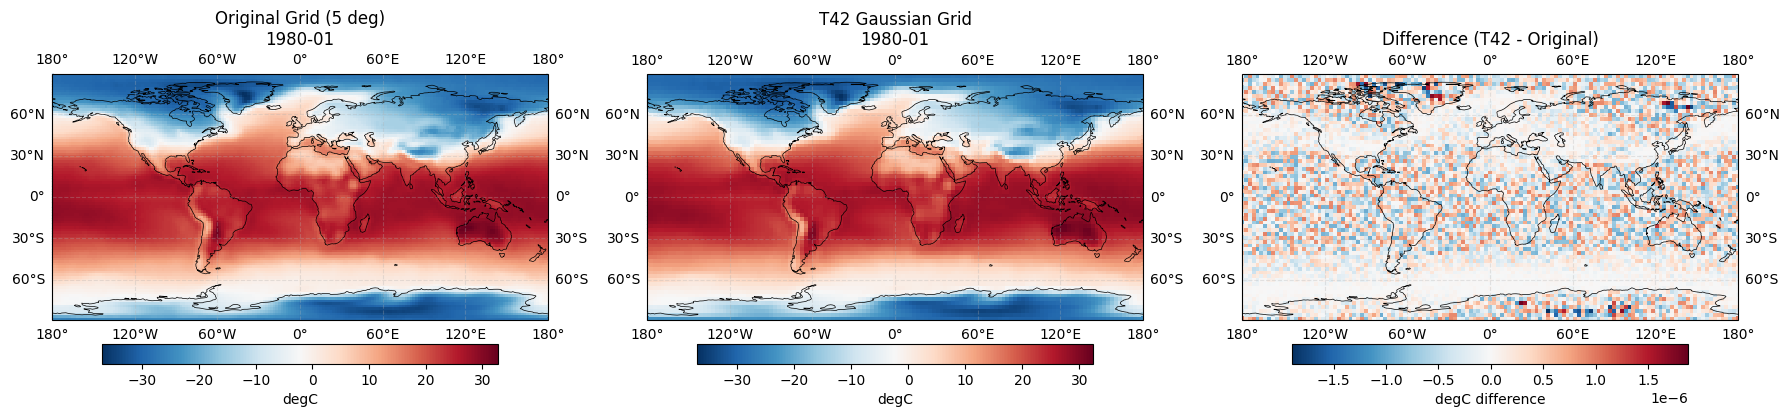

In [7]:
# Visualization with cartopy maps
# Compare original and remapped grids

fig, axes = plt.subplots(1, 3, figsize=(18, 5),
                         subplot_kw={'projection': ccrs.PlateCarree()})

t_idx = 0  # January

# Original data
im0 = axes[0].pcolormesh(ds_orig.lon, ds_orig.lat, ds_orig.temp[t_idx],
                         cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
axes[0].coastlines(linewidth=0.5)
axes[0].set_title(f'Original Grid (5 deg)\n{str(ds_orig.time[t_idx].values)[:7]}')
plt.colorbar(im0, ax=axes[0], orientation='horizontal', pad=0.05, shrink=0.8, label='degC')

# Remapped T42
im1 = axes[1].pcolormesh(ds_remap.lon, ds_remap.lat, ds_remap.temp[t_idx],
                         cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
axes[1].coastlines(linewidth=0.5)
axes[1].set_title(f'T42 Gaussian Grid\n{str(ds_remap.time[t_idx].values)[:7]}')
plt.colorbar(im1, ax=axes[1], orientation='horizontal', pad=0.05, shrink=0.8, label='degC')

# Difference
diff = ds_remap.temp[t_idx] - ds_orig.temp[t_idx].interp_like(ds_remap.isel(time=t_idx))
im2 = axes[2].pcolormesh(ds_remap.lon, ds_remap.lat, diff,
                         cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
axes[2].coastlines(linewidth=0.5)
axes[2].set_title('Difference (T42 - Original)')
plt.colorbar(im2, ax=axes[2], orientation='horizontal', pad=0.05, shrink=0.8, label='degC difference')

for ax in axes:
    ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

=== Complete Workflow Results ===
Global mean temperature range: 12.67 to 16.37 degC
Linear trend: 0.0010 degC/year
Detrended std dev: 1.3238 degC


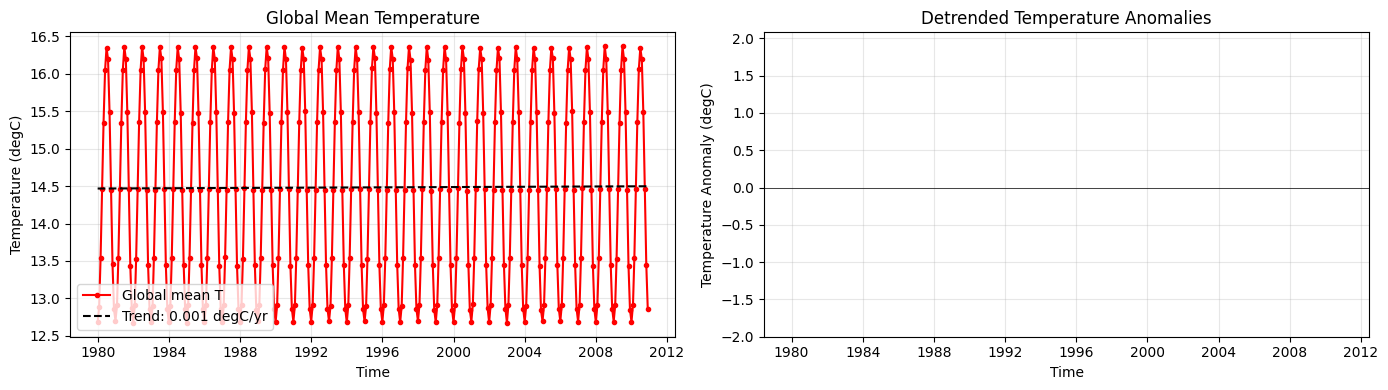

In [8]:
# Complete workflow: raw data -> CDO processing -> Python analysis -> visualization

# Step 1: Real reanalysis data loaded above
# Step 2: CDO processing - compute annual cycle components

def cdo_run(cmd_list):
    result = subprocess.run(cmd_list, capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f'CDO failed: {result.stderr}')
    return result.stdout

# Compute global field mean for each timestep
fldmean_file = os.path.join(output_dir, 'global_fldmean.nc')
cdo_run([CDO, 'fldmean', input_file, fldmean_file])

# Detrend the data
detrend_file = os.path.join(output_dir, 'detrended.nc')
cdo_run([CDO, 'detrend', fldmean_file, detrend_file])

# Step 3: Python analysis
ds_fldmean = xr.open_dataset(fldmean_file)
ds_detrend = xr.open_dataset(detrend_file)

# Compute linear trend
years = np.arange(len(ds_fldmean.time))
slope, intercept = np.polyfit(years, ds_fldmean.temp.values.ravel(), 1)
trend_per_year = slope * 12  # months per year

print('=== Complete Workflow Results ===')
print(f'Global mean temperature range: '
      f'{ds_fldmean.temp.values.min():.2f} to {ds_fldmean.temp.values.max():.2f} degC')
print(f'Linear trend: {trend_per_year:.4f} degC/year')
print(f'Detrended std dev: {ds_detrend.temp.values.std():.4f} degC')

# Step 4: Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Time series
axes[0].plot(ds_fldmean.time, ds_fldmean.temp.values.ravel(), 'o-', color='red', markersize=3, label='Global mean T')
axes[0].plot(ds_fldmean.time, intercept + slope * years, 'k--', label=f'Trend: {trend_per_year:.3f} degC/yr')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Temperature (degC)')
axes[0].set_title('Global Mean Temperature')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Detrended anomalies
axes[1].bar(ds_detrend.time, ds_detrend.temp.values.ravel(), width=20, color='steelblue', alpha=0.7)
axes[1].axhline(y=0, color='black', linewidth=0.5)
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Temperature Anomaly (degC)')
axes[1].set_title('Detrended Temperature Anomalies')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Exercises

1. Extend the workflow to compute and plot the spatial pattern of the trend (use `cdo trend` on the full 3D field)
2. Create a pipeline that computes monthly anomalies, masks the Arctic (>60N), and computes area-weighted means
3. Use `cdo merge` to combine multiple variables and `cdo expr` to compute derived quantities (e.g., dew point)
4. Implement a CDO wrapper class in Python with methods for common operations
5. Process the data through a full chain: subselect region -> remap -> smooth -> compute seasonal cycle -> visualize

Spatial trend pattern:
  Trend units: degC per timestep (monthly)
  Min trend: -54.305408
  Max trend: 29.669221


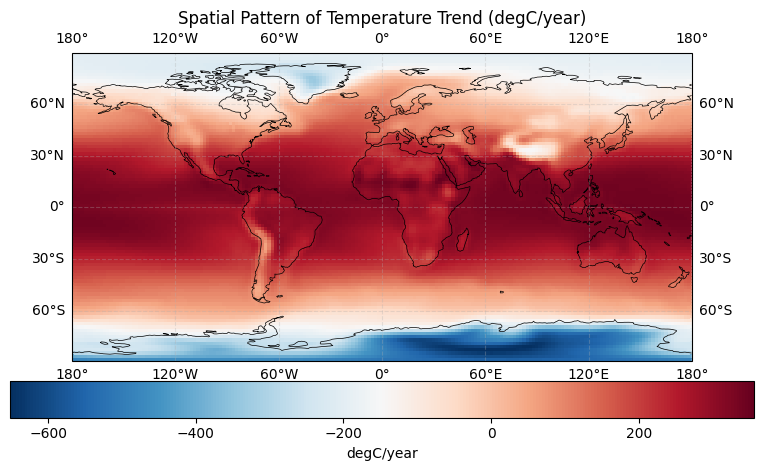

In [9]:
# Exercise 1: Spatial pattern of trend
trend_slope_file = os.path.join(output_dir, 'trend_slope.nc')
trend_intercept_file = os.path.join(output_dir, 'trend_intercept.nc')

cdo_run([CDO, 'trend', input_file, trend_slope_file, trend_intercept_file])

ds_trend = xr.open_dataset(trend_slope_file)

print('Spatial trend pattern:')
print(f'  Trend units: degC per timestep (monthly)')
print(f'  Min trend: {ds_trend.temp.values.min():.6f}')
print(f'  Max trend: {ds_trend.temp.values.max():.6f}')

# Visualize
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
im = ax.pcolormesh(ds_trend.lon, ds_trend.lat, ds_trend.temp[0] * 12,
                    cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
plt.colorbar(im, label='degC/year', orientation='horizontal', pad=0.05, shrink=0.8)
ax.coastlines(linewidth=0.5)
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
plt.title('Spatial Pattern of Temperature Trend (degC/year)')
plt.show()

In [10]:
# Exercise 4: CDO wrapper class
class CDOWorkflow:
    """Simple CDO wrapper for common operations."""

    def __init__(self, workdir='.'):
        self.workdir = workdir
        self.temp_files = []

    def _run(self, operator, input_file, output_file=None, options=''):
        if output_file is None:
            output_file = os.path.join(self.workdir, f'temp_{len(self.temp_files)}.nc')
            self.temp_files.append(output_file)
        cmd = [CDO] + options.split() + [operator, input_file, output_file]
        subprocess.run(cmd, check=True, capture_output=True)
        return output_file

    def fldmean(self, input_file):
        return self._run('fldmean', input_file)

    def timmean(self, input_file):
        return self._run('timmean', input_file)

    def sellonlatbox(self, input_file, lon1, lon2, lat1, lat2):
        op = f'sellonlatbox,{lon1},{lon2},{lat1},{lat2}'
        return self._run(op, input_file)

    def cleanup(self):
        for f in self.temp_files:
            if os.path.exists(f):
                os.remove(f)

# Test the wrapper
wf = CDOWorkflow(output_dir)
fldmean_file = wf.fldmean(input_file)
result_file = wf.timmean(fldmean_file)
ds_result = xr.open_dataset(result_file).load()
print(f'CDO Wrapper test - Global mean temperature: {ds_result.temp.values.ravel()[0]:.2f} degC')
ds_result.close()
wf.cleanup()
print('Temporary files cleaned up')

CDO Wrapper test - Global mean temperature: 14.48 degC
Temporary files cleaned up
